<a href="https://colab.research.google.com/github/Dedeepya0510/CSA4703---Deep-Learning/blob/main/Lab%20Experiment/Exp_17.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

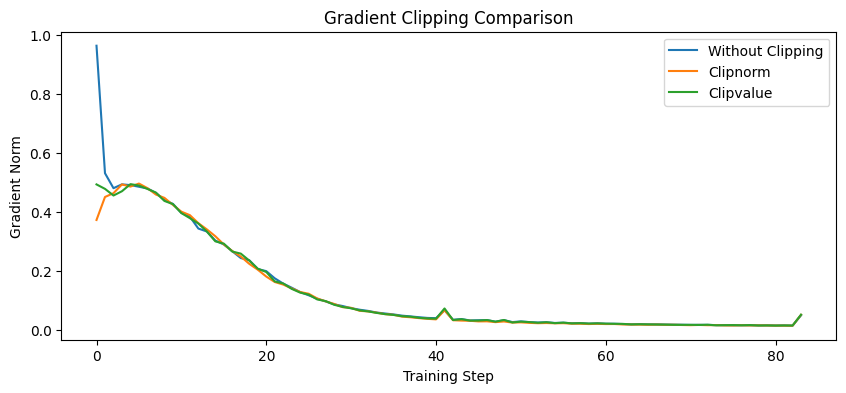

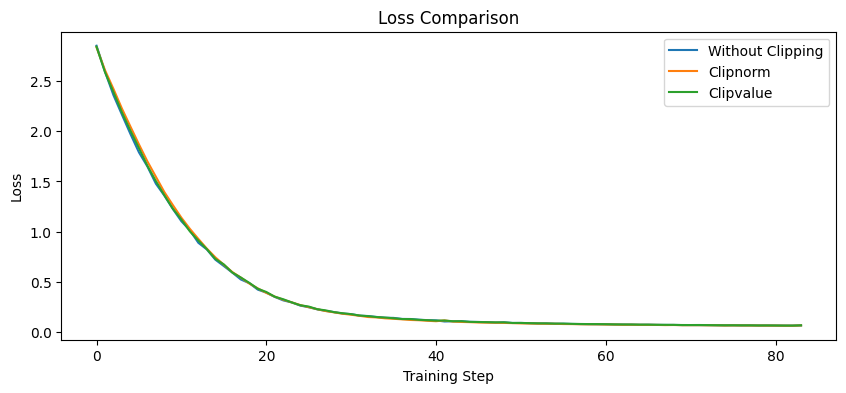

Maximum gradient without clipping: 0.96489435
Maximum gradient with clipnorm: 0.49713603
Maximum gradient with clipvalue: 0.4951325
Recommended clipping method: Clipnorm = 1.0


In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# Small character-level text corpus
text = ("deep learning is useful for artificial intelligence. " * 100)

chars = sorted(set(text))
char_to_id = {c:i for i,c in enumerate(chars)}
encoded = np.array([char_to_id[c] for c in text])

# Prepare character sequences
length = 30
X, y = [], []

for i in range(len(encoded)-length):
    X.append(encoded[i:i+length])
    y.append(encoded[i+1:i+length+1])

X = np.array(X)
y = np.array(y)

def train_model(method):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(length,)),
        tf.keras.layers.Embedding(len(chars), 16),
        tf.keras.layers.SimpleRNN(32, return_sequences=True),
        tf.keras.layers.Dense(len(chars))
    ])

    optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)
    loss_fn = tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    )

    norms, losses = [], []

    for epoch in range(2):
        for start in range(0, len(X), 128):
            xb = X[start:start+128]
            yb = y[start:start+128]

            with tf.GradientTape() as tape:
                output = model(xb, training=True)
                loss = loss_fn(yb, output)

            grads = tape.gradient(loss, model.trainable_variables)
            norm = tf.linalg.global_norm(grads).numpy()

            norms.append(norm)
            losses.append(float(loss.numpy()))

            if method == 'clipnorm':
                grads, _ = tf.clip_by_global_norm(grads, 1.0)

            elif method == 'clipvalue':
                grads = [
                    tf.clip_by_value(g, -0.5, 0.5)
                    for g in grads
                ]

            optimizer.apply_gradients(
                zip(grads, model.trainable_variables)
            )

    return norms, losses

# Train with three settings
n1, l1 = train_model('none')
n2, l2 = train_model('clipnorm')
n3, l3 = train_model('clipvalue')

# Gradient norm comparison
plt.figure(figsize=(10, 4))
plt.plot(n1, label='Without Clipping')
plt.plot(n2, label='Clipnorm')
plt.plot(n3, label='Clipvalue')
plt.xlabel("Training Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Clipping Comparison")
plt.legend()
plt.show()

# Loss comparison
plt.figure(figsize=(10, 4))
plt.plot(l1, label='Without Clipping')
plt.plot(l2, label='Clipnorm')
plt.plot(l3, label='Clipvalue')
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("Loss Comparison")
plt.legend()
plt.show()

print("Maximum gradient without clipping:", max(n1))
print("Maximum gradient with clipnorm:", max(n2))
print("Maximum gradient with clipvalue:", max(n3))
print("Recommended clipping method: Clipnorm = 1.0")